
# 02. Data Preprocessing and Preparation

## Objective
Prepare the FETAL_PLANES_DB dataset for deep learning model training.

## Tasks
1. Load and verify the dataset metadata.
2. Configure image and metadata paths.
3. Preserve the original patient-level test split.
4. Create a patient-level training and validation split.
5. Define image preprocessing and augmentation.
6. Prepare PyTorch Dataset and DataLoaders.

## Dataset
- Total images: 12,400
- Training images: 7,129
- Testing images: 5,271
- Unique patients: 1,792
- Classes: 6


In [1]:

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.model_selection import GroupShuffleSplit

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Libraries imported successfully!")
print("PyTorch:", torch.__version__)


Libraries imported successfully!
PyTorch: 2.15.0+cpu


In [2]:

PROJECT_DIR = Path.cwd().parent

DATA_DIR = PROJECT_DIR / "data"
IMAGE_DIR = DATA_DIR / "Images"
CSV_PATH = DATA_DIR / "FETAL_PLANES_DB_data.csv"

MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"

MODEL_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

print("Project:", PROJECT_DIR)
print("Images directory exists:", IMAGE_DIR.exists())
print("CSV exists:", CSV_PATH.exists())
print("Image directory:", IMAGE_DIR)


Project: C:\B.tech\Project\Fetal_Ultrasound_Project
Images directory exists: True
CSV exists: True
Image directory: C:\B.tech\Project\Fetal_Ultrasound_Project\data\Images


In [3]:

df = pd.read_csv(CSV_PATH, sep=";")
df.columns = df.columns.str.strip()

# Normalize image names
df["Image_name"] = df["Image_name"].astype(str)

# Create image paths
df["image_path"] = df["Image_name"].apply(
    lambda name: IMAGE_DIR / f"{name}.png"
)

print("Dataset shape:", df.shape)
print("Missing image paths:", (~df["image_path"].apply(
    lambda p: p.exists()
)).sum())

display(df.head())


Dataset shape: (12400, 8)
Missing image paths: 0


,Image_name,Patient_num,Plane,Brain_plane,Operator,US_Machine,Train,image_path
0,Patient00001_Plane1_1_of_15,1,Other,Not A Brain,Other,Aloka,1,C:\B.tech\Project\Fetal_Ultrasound_Project\dat...
1,Patient00001_Plane1_2_of_15,1,Other,Not A Brain,Other,Aloka,1,C:\B.tech\Project\Fetal_Ultrasound_Project\dat...
2,Patient00001_Plane1_3_of_15,1,Other,Not A Brain,Other,Aloka,1,C:\B.tech\Project\Fetal_Ultrasound_Project\dat...
3,Patient00001_Plane1_4_of_15,1,Other,Not A Brain,Other,Aloka,1,C:\B.tech\Project\Fetal_Ultrasound_Project\dat...
4,Patient00001_Plane1_5_of_15,1,Other,Not A Brain,Other,Aloka,1,C:\B.tech\Project\Fetal_Ultrasound_Project\dat...


In [4]:

# Preserve official original split
original_train_df = df[df["Train"] == 1].copy()
test_df = df[df["Train"] == 0].copy()

# Split training patients into train and validation
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=SEED
)

train_idx, val_idx = next(
    splitter.split(
        original_train_df,
        groups=original_train_df["Patient_num"]
    )
)

train_df = original_train_df.iloc[train_idx].copy()
val_df = original_train_df.iloc[val_idx].copy()

# Verify patient-level separation
train_patients = set(train_df["Patient_num"])
val_patients = set(val_df["Patient_num"])
test_patients = set(test_df["Patient_num"])

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nTraining patients:", len(train_patients))
print("Validation patients:", len(val_patients))
print("Testing patients:", len(test_patients))

print("\nTrain-Validation overlap:",
      len(train_patients & val_patients))

print("Train-Test overlap:",
      len(train_patients & test_patients))

print("Validation-Test overlap:",
      len(val_patients & test_patients))


Training images: 6217
Validation images: 912
Testing images: 5271

Training patients: 761
Validation patients: 135
Testing patients: 896

Train-Validation overlap: 0
Train-Test overlap: 0
Validation-Test overlap: 0


,Train,Validation,Test
Plane,,,
Fetal abdomen,311,42,358
Fetal brain,1397,223,1472
Fetal femur,453,63,524
Fetal thorax,922,136,660
Maternal cervix,825,156,645
Other,2309,292,1612


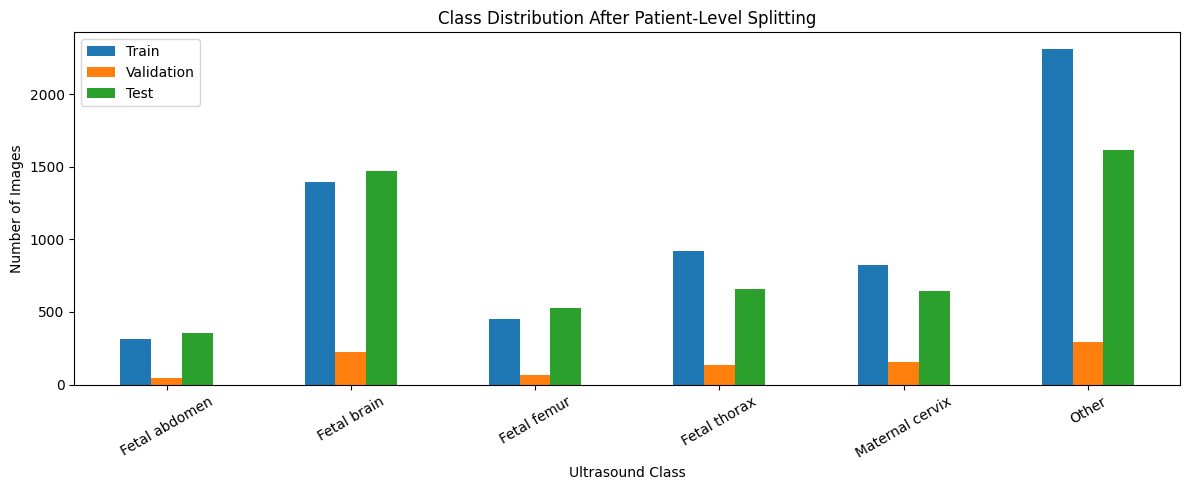

In [5]:

class_distribution = pd.DataFrame({
    "Train": train_df["Plane"].value_counts(),
    "Validation": val_df["Plane"].value_counts(),
    "Test": test_df["Plane"].value_counts()
}).fillna(0).astype(int)

display(class_distribution)

class_distribution.plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Class Distribution After Patient-Level Splitting")
plt.xlabel("Ultrasound Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()



## 7. Image Preprocessing and Transformation

### Objective
Prepare ultrasound images for ResNet18 using consistent resizing, tensor conversion and ImageNet normalization.

Training images will receive moderate augmentation, while validation and test images will only receive deterministic preprocessing.


In [6]:

# ImageNet normalization values
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Training transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(degrees=10),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

# Validation and test transformations
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

print("Training transformations ready.")
print("Evaluation transformations ready.")


Training transformations ready.
Evaluation transformations ready.



## 8. Custom PyTorch Dataset

Create a custom Dataset class to load ultrasound images and their corresponding anatomical class labels.


In [7]:

# Consistent class-to-index mapping
classes = sorted(df["Plane"].unique())

class_to_idx = {
    label: idx for idx, label in enumerate(classes)
}

idx_to_class = {
    idx: label for label, idx in class_to_idx.items()
}

print("Class mapping:", class_to_idx)


class FetalUltrasoundDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image = Image.open(row["image_path"]).convert("RGB")
        label = class_to_idx[row["Plane"]]

        if self.transform:
            image = self.transform(image)

        return image, label


Class mapping: {'Fetal abdomen': 0, 'Fetal brain': 1, 'Fetal femur': 2, 'Fetal thorax': 3, 'Maternal cervix': 4, 'Other': 5}


In [8]:

BATCH_SIZE = 16
NUM_WORKERS = 0  # Safe default for Windows

train_dataset = FetalUltrasoundDataset(
    train_df, train_transform
)

val_dataset = FetalUltrasoundDataset(
    val_df, eval_transform
)

test_dataset = FetalUltrasoundDataset(
    test_df, eval_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))


Training batches: 389
Validation batches: 57
Testing batches: 330


In [9]:

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Labels:", labels[:10].tolist())

print("\nNumber of classes:", len(classes))


Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
Image dtype: torch.float32
Labels: [4, 2, 1, 1, 1, 1, 2, 0, 4, 1]

Number of classes: 6


In [10]:
SPLIT_DIR = DATA_DIR / "splits"
SPLIT_DIR.mkdir(exist_ok=True)

train_df.drop(columns=["image_path"]).to_csv(
    SPLIT_DIR / "train.csv", index=False
)

val_df.drop(columns=["image_path"]).to_csv(
    SPLIT_DIR / "validation.csv", index=False
)

test_df.drop(columns=["image_path"]).to_csv(
    SPLIT_DIR / "test.csv", index=False
)

print("All dataset splits saved successfully!")

All dataset splits saved successfully!
